# COVID-QU-Ex → tách COVID-19 / Normal (chỉ ảnh) → đẩy lên Hugging Face

Notebook này:
1. Tìm thư mục COVID-QU-Ex (tự dò trên Kaggle/local).
2. Lấy **ảnh** lớp `COVID-19` và `Normal`, giữ nguyên chia Train/Val/Test gốc, **không lấy mask**.
3. Kiểm tra ảnh lỗi và ảnh trùng giữa các split.
4. Tạo bộ dữ liệu gọn + `manifest.csv` + dataset card (`README.md`).
5. Đẩy lên Hugging Face: `dacntt-kltn/covid-normal-cxr` (đổi tên ở ô cấu hình nếu muốn).

**Token Hugging Face:** cần token quyền *write* thuộc tài khoản có quyền ghi vào org `dacntt-kltn`.
Trên Kaggle: *Add-ons → Secrets* → thêm secret tên `HF_TOKEN`. Không dán token trực tiếp vào code hay chia sẻ nó.

## 1. Cài đặt và cấu hình

In [1]:
!pip install -q -U huggingface_hub datasets
!pip install -q kagglehub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
from pathlib import Path
import os, json, shutil, hashlib
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

# Nguồn
SRC_ROOT = None
SRC_SUBSET = "Lung Segmentation Data"
CLASS_MAP = {"Normal": "normal", "COVID-19": "covid19"}   # normal=0, covid19=1
SPLITS = ["train", "val", "test"]
CLASS_TO_IDX = {v: i for i, v in enumerate(CLASS_MAP.values())}

# Xử lý ảnh (None = chép nguyên file gốc)
RESIZE = None # vd (256, 256)
GRAYSCALE = False
IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
DROP_CROSS_SPLIT_DUP = False

# Hugging Face
HF_REPO_ID = "dacntt-kltn/covid-normal-cxr"
PRIVATE = False

OUT_ROOT = Path("/kaggle/working/covid_normal_cxr") if Path("/kaggle").exists() else Path("./covid_normal_cxr")
print(OUT_ROOT.resolve(), CLASS_TO_IDX)

/kaggle/working/covid_normal_cxr {'normal': 0, 'covid19': 1}


## 2. Tìm dữ liệu gốc

In [3]:
import kagglehub

KAGGLE_HANDLE = "anasmohammedtahir/covidqu"

dl_path = Path(kagglehub.dataset_download(KAGGLE_HANDLE))

if (dl_path / SRC_SUBSET).is_dir():
    SRC_ROOT = dl_path
else:
    SRC_ROOT = next(p.parent for p in dl_path.rglob(SRC_SUBSET) if p.is_dir())

SRC = SRC_ROOT / SRC_SUBSET
print("SRC =", SRC, [p.name for p in SRC.iterdir()])

SRC = /kaggle/input/datasets/anasmohammedtahir/covidqu/Lung Segmentation Data ['Lung Segmentation Data']


## 3. Quét ảnh (chỉ thư mục `images`, bỏ qua mask)

In [6]:
# Xem cấu trúc 3 cấp đầu
for p in sorted(SRC.rglob("*")):
    if p.is_dir() and len(p.relative_to(SRC).parts) <= 3:
        print("  " * (len(p.relative_to(SRC).parts) - 1) + p.name + "/")

# Tự tìm thư mục thực sự chứa các split
def has_splits(d: Path):
    names = {c.name.lower() for c in d.iterdir() if c.is_dir()}
    return set(SPLITS) <= names

if has_splits(SRC):
    DATA_DIR = SRC
else:
    DATA_DIR = next((d for d in SRC.rglob("*") if d.is_dir() and has_splits(d)), None)
assert DATA_DIR is not None, "Không tìm thấy thư mục chứa train/val/test, hãy gửi phần cấu trúc in ở trên"
print("DATA_DIR =", DATA_DIR)

Lung Segmentation Data/
  Test/
    COVID-19/
    Non-COVID/
    Normal/
  Train/
    COVID-19/
    Non-COVID/
    Normal/
  Val/
    COVID-19/
    Non-COVID/
    Normal/
DATA_DIR = /kaggle/input/datasets/anasmohammedtahir/covidqu/Lung Segmentation Data/Lung Segmentation Data


In [8]:
def child_ci(parent: Path, name: str):
    for p in parent.iterdir():
        if p.is_dir() and p.name.lower() == name.lower():
            return p
    return None

rows = []
for split in SPLITS:
    split_dir = child_ci(DATA_DIR, split)
    assert split_dir is not None, f"Không thấy split '{split}' trong {SRC}"
    for src_cls, new_cls in CLASS_MAP.items():
        cls_dir = child_ci(split_dir, src_cls)
        assert cls_dir is not None, f"Không thấy lớp '{src_cls}' trong {split_dir}"
        img_dir = child_ci(cls_dir, "images")
        assert img_dir is not None, f"Không thấy thư mục 'images' trong {cls_dir}"
        for f in sorted(img_dir.iterdir()):
            if f.suffix.lower() in IMG_EXTS:
                rows.append(dict(split=split, label=new_cls, label_idx=CLASS_TO_IDX[new_cls],
                                 orig_name=f.name, orig_rel_path=str(f.relative_to(SRC_ROOT)),
                                 src_path=str(f)))
df = pd.DataFrame(rows)
print(len(df), "ảnh")
display(df.groupby(["split", "label"]).size().unstack())

22657 ảnh


label,covid19,normal
split,,
test,2395,2140
train,7658,6849
val,1903,1712


## 4. Kiểm tra trùng lặp

In [9]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while b := f.read(chunk):
            h.update(b)
    return h.hexdigest()

df["sha256"] = [sha256(p) for p in tqdm(df.src_path, desc="hash")]
dup = df[df.duplicated("sha256", keep=False)]
cross = dup.groupby("sha256").filter(lambda g: g.split.nunique() > 1)
print(f"Trùng nội dung: {len(dup)} dòng | trùng GIỮA các split: {len(cross)} dòng")
assert len(df[df.duplicated(["split", "label", "orig_name"], keep=False)]) == 0, "Trùng tên trong cùng split/lớp"

hash:   0%|          | 0/22657 [00:00<?, ?it/s]

Trùng nội dung: 0 dòng | trùng GIỮA các split: 0 dòng


## 5. Tạo bộ dữ liệu cục bộ

In [10]:
work = df.copy()
if DROP_CROSS_SPLIT_DUP and len(cross):
    work["_o"] = work.split.map({"train": 0, "val": 1, "test": 2})
    work = work.sort_values("_o").drop_duplicates("sha256", keep="first").drop(columns="_o")
    print("Đã loại", len(df) - len(work), "ảnh trùng")

if OUT_ROOT.exists():
    shutil.rmtree(OUT_ROOT)
out_rows = []
for r in tqdm(work.itertuples(index=False), total=len(work), desc="copy"):
    dst_dir = OUT_ROOT / r.split / r.label
    dst_dir.mkdir(parents=True, exist_ok=True)
    if RESIZE is None and not GRAYSCALE:
        dst = dst_dir / r.orig_name
        shutil.copy2(r.src_path, dst)
        with Image.open(dst) as im:
            w, h, mode = im.width, im.height, im.mode
    else:
        dst = dst_dir / (Path(r.orig_name).stem + ".png")
        with Image.open(r.src_path) as im:
            im = im.convert("L") if GRAYSCALE else im.convert("RGB")
            if RESIZE:
                im = im.resize(RESIZE, Image.BICUBIC)
            im.save(dst)
            w, h, mode = im.width, im.height, im.mode
    out_rows.append(dict(file=str(dst.relative_to(OUT_ROOT)).replace(os.sep, "/"),
                         split=r.split, label=r.label, label_idx=r.label_idx,
                         orig_name=r.orig_name, orig_rel_path=r.orig_rel_path,
                         sha256=r.sha256, w=w, h=h, mode=mode))

manifest = pd.DataFrame(out_rows).sort_values(["split", "label", "file"]).reset_index(drop=True)
manifest.to_csv(OUT_ROOT / "manifest.csv", index=False)
(OUT_ROOT / "meta.json").write_text(json.dumps(dict(
    source="COVID-QU-Ex", source_subset=SRC_SUBSET, class_to_idx=CLASS_TO_IDX,
    resize=RESIZE, grayscale=GRAYSCALE, dropped_cross_split_dup=DROP_CROSS_SPLIT_DUP,
    counts=manifest.groupby(["split", "label"]).size().unstack().to_dict()), indent=2))
display(manifest.groupby(["split", "label"]).size().unstack())

copy:   0%|          | 0/22657 [00:00<?, ?it/s]

label,covid19,normal
split,,
test,2395,2140
train,7658,6849
val,1903,1712


## 6. Kiểm tra trước khi đẩy lên

In [11]:
bad = []
for f in tqdm(manifest.file, desc="verify"):
    try:
        with Image.open(OUT_ROOT / f) as im:
            im.verify()
    except Exception as e:
        bad.append((f, str(e)))
print("Ảnh lỗi:", len(bad))
assert not bad, bad[:5]
display(manifest.groupby(["w", "h", "mode"]).size())

verify:   0%|          | 0/22657 [00:00<?, ?it/s]

Ảnh lỗi: 0


w    h    mode
256  256  L       22657
dtype: int64

## 7. Dataset card (`README.md`)

Phần YAML khai báo split (`val` → `validation`) và **thứ tự nhãn** (`normal=0`, `covid19=1`) để `load_dataset` cho đúng nhãn như `manifest.csv`.

In [12]:
counts = manifest.groupby(["split", "label"]).size().unstack()
count_md = counts.to_markdown() if hasattr(counts, "to_markdown") else counts.to_string()

card = f"""---
pretty_name: COVID-QU-Ex (COVID-19 vs Normal, images only)
task_categories:
- image-classification
tags:
- medical
- chest-x-ray
- covid-19
configs:
- config_name: default
  data_files:
  - split: train
    path: train/**
  - split: validation
    path: val/**
  - split: test
    path: test/**
  features:
  - name: image
    dtype: image
  - name: label
    dtype:
      class_label:
        names:
          '0': normal
          '1': covid19
---

# COVID-QU-Ex: COVID-19 vs Normal (images only)

Tập con của **COVID-QU-Ex** (Qatar University) gồm ảnh X-quang ngực của 2 lớp `covid19` và `normal`.
Giữ nguyên chia Train/Val/Test gốc. **Không** chứa lung mask hay infection mask.

- Nguồn: bộ `{SRC_SUBSET}` của COVID-QU-Ex
- Nhãn: `normal=0`, `covid19=1`
- `manifest.csv`: mỗi ảnh một dòng (split, label, sha256, kích thước, `orig_rel_path` để đối chiếu dữ liệu gốc)

{count_md}

## Dùng

```python
from datasets import load_dataset
ds = load_dataset("{HF_REPO_ID}")
print(ds)
```

## Nguồn và giấy phép
https://www.kaggle.com/datasets/anasmohammedtahir/covidqu

[1] A. M. Tahir, M. E. H. Chowdhury, A. Khandakar, Y. Qiblawey, U. Khurshid, S. Kiranyaz, N. Ibtehaz, M. S. Rahman, S. Al-Madeed, S. Mahmud, M. Ezeddin, K. Hameed, and T. Hamid, “COVID-19 Infection Localization and Severity Grading from Chest X-ray Images”, Computers in Biology and Medicine, vol. 139, p. 105002, 2021, https://doi.org/10.1016/j.compbiomed.2021.105002.
[2] Anas M. Tahir, Muhammad E. H. Chowdhury, Yazan Qiblawey, Amith Khandakar, Tawsifur Rahman, Serkan Kiranyaz, Uzair Khurshid, Nabil Ibtehaz, Sakib Mahmud, and Maymouna Ezeddin, “COVID-QU-Ex .” Kaggle, 2021, https://doi.org/10.34740/kaggle/dsv/3122958.
[3] T. Rahman, A. Khandakar, Y. Qiblawey A. Tahir S. Kiranyaz, S. Abul Kashem, M. Islam, S. Al Maadeed, S. Zughaier, M. Khan, M. Chowdhury, "Exploring the Effect of Image Enhancement Techniques on COVID-19 Detection using Chest X-rays Images," Computers in Biology and Medicine, p. 104319, 2021, https://doi.org/10.1016/j.compbiomed.2021.104319.
[4] A. Degerli, M. Ahishali, M. Yamac, S. Kiranyaz, M. E. H. Chowdhury, K. Hameed, T. Hamid, R. Mazhar, and M. Gabbouj, "Covid-19 infection map generation and detection from chest X-ray images," Health Inf Sci Syst 9, 15 (2021), https://doi.org/10.1007/s13755-021-00146-8.
[5] M. E. H. Chowdhury, T. Rahman, A. Khandakar, R. Mazhar, M. A. Kadir, Z. B. Mahbub, K. R. Islam, M. S. Khan, A. Iqbal, N. A. Emadi, M. B. I. Reaz, M. T. Islam, "Can AI Help in Screening Viral and COVID-19 Pneumonia?," IEEE Access, vol. 8, pp. 132665-132676, 2020, https://doi.org/10.1109/ACCESS.2020.3010287.
"""
(OUT_ROOT / "README.md").write_text(card, encoding="utf-8")
print(card[:600])

---
pretty_name: COVID-QU-Ex (COVID-19 vs Normal, images only)
task_categories:
- image-classification
tags:
- medical
- chest-x-ray
- covid-19
configs:
- config_name: default
  data_files:
  - split: train
    path: train/**
  - split: validation
    path: val/**
  - split: test
    path: test/**
  features:
  - name: image
    dtype: image
  - name: label
    dtype:
      class_label:
        names:
          '0': normal
          '1': covid19
---

# COVID-QU-Ex: COVID-19 vs Normal (images only)

Tập con của **COVID-QU-Ex** (Qatar University) gồm ảnh X-quang ngực của 2 lớp `covid19` và `norm


## 8. Đăng nhập Hugging Face

In [13]:
import getpass
from huggingface_hub import login, HfApi

token = os.environ.get("HF_TOKEN")
if not token:
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass
if not token:
    token = getpass.getpass("Nhập HF token (quyền write): ")

login(token=token, add_to_git_credential=False)
api = HfApi()
print("Đăng nhập là:", api.whoami()["name"])

Đăng nhập là: lpv30


## 9. Tạo repo dataset và upload

In [16]:
api.create_repo(HF_REPO_ID, repo_type="dataset", private=PRIVATE, exist_ok=True)

# upload_large_folder: chia nhỏ, tự resume nếu bị ngắt 
api.upload_folder(
    repo_id=HF_REPO_ID,
    repo_type="dataset",
    folder_path=str(OUT_ROOT),
)
print("Xong:", f"https://huggingface.co/datasets/{HF_REPO_ID}")

Xong: https://huggingface.co/datasets/dacntt-kltn/covid-normal-cxr


## 10. Kiểm tra sau khi upload

In [17]:
files = api.list_repo_files(HF_REPO_ID, repo_type="dataset")
n_img = sum(Path(f).suffix.lower() in IMG_EXTS for f in files)
print("Số ảnh trên Hugging Face:", n_img, "| trong manifest:", len(manifest))
print("Có README/manifest/meta:", {k: k in files for k in ["README.md", "manifest.csv", "meta.json"]})

Số ảnh trên Hugging Face: 22657 | trong manifest: 22657
Có README/manifest/meta: {'README.md': True, 'manifest.csv': True, 'meta.json': True}


Resolving data files:   0%|          | 0/14507 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3615 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/4535 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/14507 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/3615 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/4535 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 14507
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 3615
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 4535
    })
})
['normal', 'covid19']


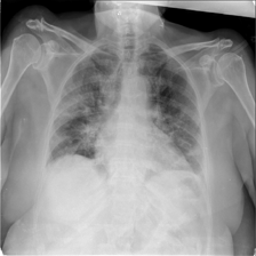

In [19]:
from datasets import load_dataset
import datasets
datasets.disable_progress_bars()
ds = load_dataset(HF_REPO_ID)
print(ds)
print(ds["train"].features["label"].names)
ds["train"][0]["image"]